<a href="https://colab.research.google.com/github/Jayanta-404/Emotion_Recognition_From_Text/blob/main/Emotion_recognition.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install pandas numpy scikit-learn matplotlib seaborn \
    tensorflow gensim joblib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 32.6 MB/s eta 0:00:00


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving test.txt to test.txt
Saving train.txt to train.txt
Saving val.txt to val.txt


In [ ]:

import os
import pandas as pd

def load_emotion_file(filename):
    rows = []

    with open(filename, "r", encoding="utf-8") as file:
        for line in file:
            line = line.strip()

            if not line or ";" not in line:
                continue

            text, emotion = line.rsplit(";", 1)

            rows.append({
                "text": text.strip(),
                "emotion": emotion.strip().lower()
            })

    return pd.DataFrame(rows)

train_df = load_emotion_file("/content/train (1).txt")
val_df = load_emotion_file("/content/val (1).txt")
test_df = load_emotion_file("/content/test (1).txt")

print("Dataset loaded successfully!")
print("-" * 40)
print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Testing samples:", len(test_df))
print("Total samples:", len(train_df) + len(val_df) + len(test_df))
print("\nEmotion classes:")
print(sorted(train_df["emotion"].unique()))
print("\nFirst 5 training examples:")
display(train_df.head())


Dataset loaded successfully!
----------------------------------------
Training samples: 16000
Validation samples: 2000
Testing samples: 2000
Total samples: 20000

Emotion classes:
['anger', 'fear', 'joy', 'love', 'sadness', 'surprise']

First 5 training examples:


,text,emotion
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger


In [ ]:

print("Training data information:")
train_df.info()

print("\nMissing values:")
print("Train:", train_df.isnull().sum().to_dict())
print("Validation:", val_df.isnull().sum().to_dict())
print("Test:", test_df.isnull().sum().to_dict())

print("\nTraining emotion distribution:")
print(train_df["emotion"].value_counts())


Training data information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16000 entries, 0 to 15999
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   text     16000 non-null  object
 1   emotion  16000 non-null  object
dtypes: object(2)
memory usage: 250.1+ KB

Missing values:
Train: {'text': 0, 'emotion': 0}
Validation: {'text': 0, 'emotion': 0}
Test: {'text': 0, 'emotion': 0}

Training emotion distribution:
emotion
joy         5362
sadness     4666
anger       2159
fear        1937
love        1304
surprise     572
Name: count, dtype: int64


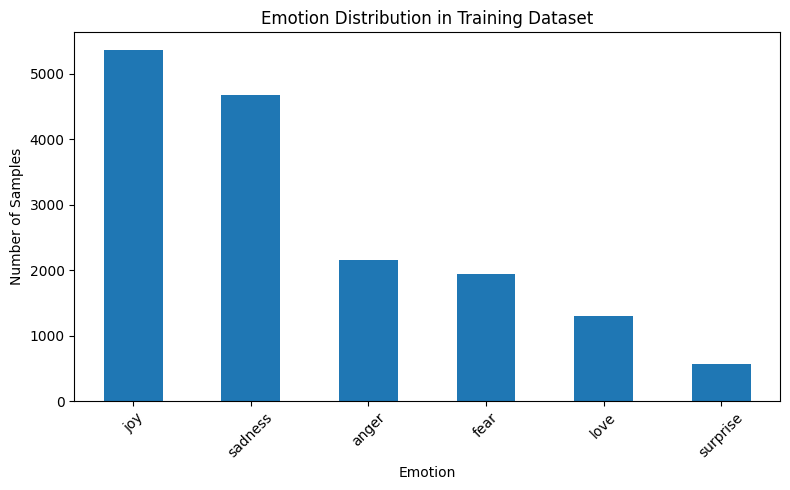

In [ ]:

import matplotlib.pyplot as plt

train_df["emotion"].value_counts().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Emotion Distribution in Training Dataset")
plt.xlabel("Emotion")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [ ]:
import re

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"@\w+", " USER ", text)
    text = re.sub(r"#(\w+)", r"\1", text)
    text = re.sub(r"[^a-z0-9\s']", " ", text)
    text = re.sub(r"\s+", " ", text).strip()

    return text


for df in [train_df, val_df, test_df]:
    df["clean_text"] = df["text"].apply(clean_text)

display(train_df[["text", "clean_text", "emotion"]].head())

,text,clean_text,emotion
0,i didnt feel humiliated,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,i am feeling grouchy,anger


In [ ]:
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight

label_encoder = LabelEncoder()
label_encoder.fit(train_df["emotion"])

y_train = label_encoder.transform(train_df["emotion"])
y_val = label_encoder.transform(val_df["emotion"])
y_test = label_encoder.transform(test_df["emotion"])

class_names = list(label_encoder.classes_)
num_classes = len(class_names)

print("Emotion mapping:")
for i, name in enumerate(class_names):
    print(i, "=", name)

print("Number of classes:", num_classes)

Emotion mapping:
0 = anger
1 = fear
2 = joy
3 = love
4 = sadness
5 = surprise
Number of classes: 6


In [ ]:
weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)

class_weights = {
    int(i): float(w)
    for i, w in enumerate(weights)
}

print("Class weights:", class_weights)

Class weights: {0: 1.2351397251814111, 1: 1.3766993632765445, 2: 0.49732686808404825, 3: 2.044989775051125, 4: 0.5715102157451064, 5: 4.662004662004662}


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

X_train_text = train_df["clean_text"]
X_val_text = val_df["clean_text"]
X_test_text = test_df["clean_text"]

tfidf = TfidfVectorizer(
    max_features=30000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train_text)
X_val_tfidf = tfidf.transform(X_val_text)
X_test_tfidf = tfidf.transform(X_test_text)

print("Training feature shape:", X_train_tfidf.shape)

Training feature shape: (16000, 30000)


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score

baseline_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ),
    "Linear SVM": LinearSVC(
        class_weight="balanced"
    )
}

baseline_results = {}

for name, model in baseline_models.items():
    model.fit(X_train_tfidf, y_train)

    val_pred = model.predict(X_val_tfidf)

    accuracy = accuracy_score(y_val, val_pred)
    macro_f1 = f1_score(
        y_val, val_pred, average="macro"
    )

    baseline_results[name] = {
        "model": model,
        "accuracy": accuracy,
        "macro_f1": macro_f1
    }

    print(f"\n{name}")
    print(f"Validation accuracy: {accuracy:.4f}")
    print(f"Validation macro F1: {macro_f1:.4f}")


Logistic Regression
Validation accuracy: 0.8780
Validation macro F1: 0.8506

Linear SVM
Validation accuracy: 0.9075
Validation macro F1: 0.8800


In [ ]:
from gensim.models import FastText

sentences = [
    text.split()
    for text in train_df["clean_text"]
]

fasttext_model = FastText(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=1,
    workers=2,
    sg=1,
    epochs=20
)

print("FastText vocabulary size:",
      len(fasttext_model.wv))

FastText vocabulary size: 15211


In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

MAX_WORDS = 30000
MAX_LEN = 60
EMBED_DIM = 100

tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(train_df["clean_text"])

X_train_seq = pad_sequences(
    tokenizer.texts_to_sequences(train_df["clean_text"]),
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_val_seq = pad_sequences(
    tokenizer.texts_to_sequences(val_df["clean_text"]),
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_test_seq = pad_sequences(
    tokenizer.texts_to_sequences(test_df["clean_text"]),
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

word_index = tokenizer.word_index
vocab_size = min(MAX_WORDS, len(word_index) + 1)

print("Vocabulary size:", vocab_size)
print("Training sequence shape:", X_train_seq.shape)

Vocabulary size: 15213
Training sequence shape: (16000, 60)


In [ ]:
embedding_matrix = np.zeros(
    (vocab_size, EMBED_DIM),
    dtype=np.float32
)

for word, index in word_index.items():
    if index >= vocab_size:
        continue

    if word in fasttext_model.wv:
        embedding_matrix[index] = fasttext_model.wv[word]

print("Embedding matrix shape:", embedding_matrix.shape)

Embedding matrix shape: (15213, 100)


In [ ]:
import tensorflow as tf
from tensorflow.keras import Model
from tensorflow.keras.layers import (
    Input, Embedding, Conv1D, GlobalMaxPooling1D,
    Bidirectional, LSTM, Dense, Dropout, Concatenate
)
from tensorflow.keras.callbacks import (
    EarlyStopping, ReduceLROnPlateau
)

tf.keras.utils.set_random_seed(42)

inputs = Input(shape=(MAX_LEN,), name="text_input")

embedding = Embedding(
    input_dim=vocab_size,
    output_dim=EMBED_DIM,
    weights=[embedding_matrix],
    trainable=True,
    mask_zero=False,
    name="fasttext_embedding"
)(inputs)

# CNN branch
cnn = Conv1D(
    filters=128,
    kernel_size=3,
    activation="relu",
    padding="same"
)(embedding)

cnn = GlobalMaxPooling1D()(cnn)
cnn = Dropout(0.3)(cnn)

# BiLSTM branch
lstm = Bidirectional(
    LSTM(64, return_sequences=False)
)(embedding)

lstm = Dropout(0.3)(lstm)

# Combine both branches
combined = Concatenate()([cnn, lstm])

combined = Dense(64, activation="relu")(combined)
combined = Dropout(0.4)(combined)

outputs = Dense(
    num_classes,
    activation="softmax",
    name="emotion_output"
)(combined)

model = Model(inputs=inputs, outputs=outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ text_input          │ (None, 60)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fasttext_embedding  │ (None, 60, 100)   │  1,521,300 │ text_input[0][0]  │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 60, 128)   │     38,528 │ fasttext_embeddi… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 128)       │          0 │ conv1d[0][0]      │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 128)       │     84,480 │ fasttext_embeddi… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ global_max_pooli… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128)       │          0 │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 256)       │          0 │ dropout[0][0],    │
│ (Concatenate)       │                   │            │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │     16,448 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 64)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ emotion_output      │ (None, 6)         │        390 │ dropout_2[0][0]   │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,661,146 (6.34 MB)

 Trainable params: 1,661,146 (6.34 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6
    )
]

history = model.fit(
    X_train_seq,
    y_train,
    validation_data=(X_val_seq, y_val),
    epochs=15,
    batch_size=64,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 45s 157ms/step - accuracy: 0.2396 - loss: 1.7258 - val_accuracy: 0.5355 - val_loss: 1.3866 - learning_rate: 0.0010
Epoch 2/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 39s 156ms/step - accuracy: 0.5875 - loss: 0.9833 - val_accuracy: 0.8590 - val_loss: 0.4504 - learning_rate: 0.0010
Epoch 3/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 42s 161ms/step - accuracy: 0.8720 - loss: 0.3713 - val_accuracy: 0.9080 - val_loss: 0.2713 - learning_rate: 0.0010
Epoch 4/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 40s 157ms/step - accuracy: 0.9147 - loss: 0.2380 - val_accuracy: 0.9140 - val_loss: 0.2611 - learning_rate: 0.0010
Epoch 5/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 40s 161ms/step - accuracy: 0.9300 - loss: 0.1913 - val_accuracy: 0.9185 - val_loss: 0.2287 - learning_rate: 0.0010
Epoch 6/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 39s 158ms/step - accuracy: 0.9403 - loss: 0.1577 - val_accuracy: 0.9195 - val_loss: 0.2191 - learning_rate: 0.0010
Epoch 7/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 41s 157ms/step - accuracy: 0.9

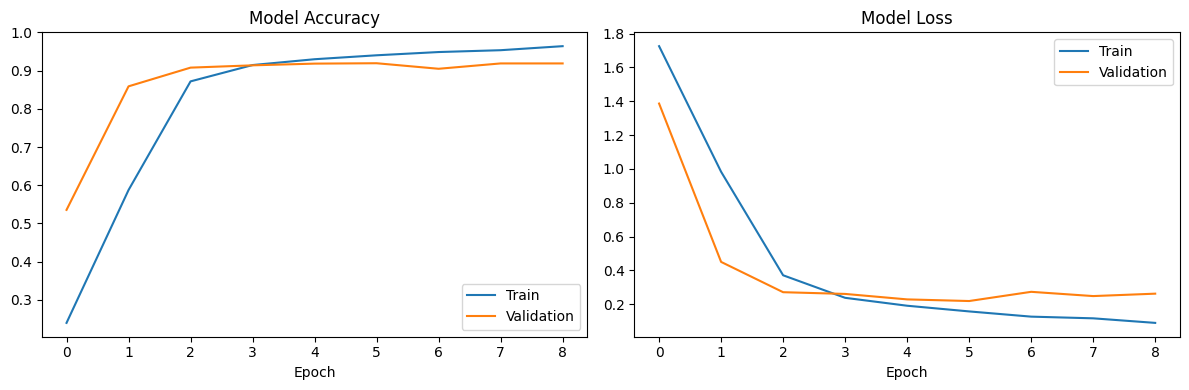

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.legend()

plt.tight_layout()
plt.show()

Test accuracy: 0.9130
Test macro F1: 0.8756

Classification Report:
              precision    recall  f1-score   support

       anger       0.90      0.94      0.92       275
        fear       0.93      0.81      0.87       224
         joy       0.95      0.91      0.93       695
        love       0.75      0.92      0.83       159
     sadness       0.98      0.93      0.95       581
    surprise       0.62      0.95      0.75        66

    accuracy                           0.91      2000
   macro avg       0.86      0.91      0.88      2000
weighted avg       0.92      0.91      0.92      2000



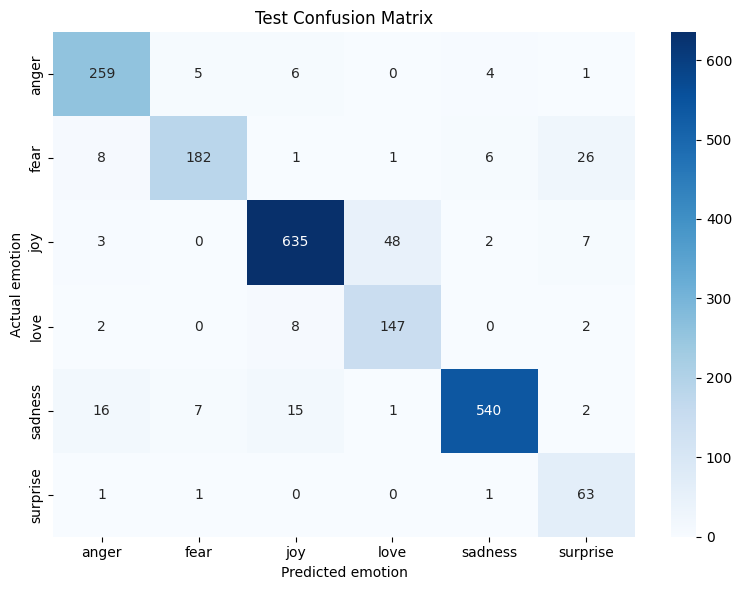

In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score
)
import seaborn as sns

test_loss, test_accuracy = model.evaluate(
    X_test_seq, y_test, verbose=0
)

probabilities = model.predict(X_test_seq, verbose=0)
y_pred = np.argmax(probabilities, axis=1)

print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test macro F1: {f1_score(y_test, y_pred, average='macro'):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(num_classes),
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(
    y_test, y_pred,
    labels=np.arange(num_classes)
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted emotion")
plt.ylabel("Actual emotion")
plt.title("Test Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
results = [
    {
        "Model": name,
        "Validation Accuracy": result["accuracy"],
        "Validation Macro F1": result["macro_f1"]
    }
    for name, result in baseline_results.items()
]

results.append({
    "Model": "CNN + BiLSTM + FastText",
    "Validation Accuracy": max(history.history["val_accuracy"]),
    "Validation Macro F1": None
})

results_df = pd.DataFrame(results)
display(results_df)

,Model,Validation Accuracy,Validation Macro F1
0,Logistic Regression,0.8780,0.850635
1,Linear SVM,0.9075,0.879958
2,CNN + BiLSTM + FastText,0.9195,NaN


In [ ]:
import json
import joblib

OUTPUT_DIR = "/content/emotion_model"
os.makedirs(OUTPUT_DIR, exist_ok=True)

model.save(f"{OUTPUT_DIR}/emotion_model.keras")

with open(f"{OUTPUT_DIR}/tokenizer.json", "w", encoding="utf-8") as f:
    f.write(tokenizer.to_json())

with open(f"{OUTPUT_DIR}/labels.json", "w", encoding="utf-8") as f:
    json.dump(class_names, f)

joblib.dump(tfidf, f"{OUTPUT_DIR}/tfidf.joblib")

for name, result in baseline_results.items():
    filename = name.lower().replace(" ", "_")
    joblib.dump(
        result["model"],
        f"{OUTPUT_DIR}/{filename}.joblib"
    )

print("Saved files:", os.listdir(OUTPUT_DIR))

Saved files: ['logistic_regression.joblib', 'labels.json', 'linear_svm.joblib', 'emotion_model.keras', 'tfidf.joblib', 'tokenizer.json']


In [ ]:
import shutil
from google.colab import files

shutil.make_archive(
    "/content/emotion_model_files",
    "zip",
    OUTPUT_DIR
)

files.download("/content/emotion_model_files.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>